# 05 · Acto 3: el LLM hace lo que sí sabe, explicar con palabras

## Qué vas a aprender

- Por qué el **fine-tuning sí funciona** cuando la tarea es de **lenguaje** (convertir información estructurada en texto), y no funcionaba cuando le pedíamos *ver* el color.
- Cómo se **fabrican datos de texto gratis**: sin fotos, sin etiquetar a mano, con unas reglas.
- A **medir automáticamente** una frase contra la verdad: ajustes en el sentido correcto, en sentido contrario y **alucinaciones** (ajustes inventados).
- Que **fluido no es lo mismo que correcto**: un modelo puede escribir frases impecables y aun así inventarse algún adjetivo.

## Dónde estamos

- **Acto 1 (notebooks 02 y 03).** Le pedíamos al LLM de visión *leer* los cinco ajustes de color de una foto. Sin entrenar copiaba los rangos del prompt; con LoRA aprendía el **formato** (100 % de JSON válidos) pero **no la tarea**: error normalizado 0,310, peor que contestar siempre la media (0,259).
- **Acto 2 (notebook 04).** Una regresión sobre 27 estadísticas de color ganaba con claridad (0,151).
- **Acto 3 (este notebook).** Le damos al LLM la tarea que sí es suya: **dado el JSON de ajustes, escribir una explicación corta en español**.

> **Aviso de tiempo.** Este notebook tarda unos **23 minutos en CPU** con los valores de clase (1397 s medidos el 21/11/2026 con papermill, 12 hilos, sin GPU): unos 3,5 minutos para A3, unos 15,5 minutos de entrenamiento (933 s) y unos 3,7 minutos para medir B3. En la ronda 4 del estudio técnico (20/11/2026) el notebook tardó 1454 s. Las salidas que ves debajo de cada celda son las de la ejecución del 21/11/2026; si lo ejecutas, tus cifras serán parecidas pero no necesariamente idénticas. Con `N_FRASES = 100` y `EPOCAS = 1` (pensado para CI) tardaría bastante menos, pero esa configuración **no se ha verificado**.

Entrada: `parejas/parejas.jsonl` de la carpeta de trabajo (solo se usan los JSON de ajustes de val y test; no se abre ninguna foto). Salida: `resultados/metricas_explicacion.json`, `resultados/explicaciones.jsonl`, `adaptador_explicacion/` y dos runs en MLflow (`A3_explicacion_one_shot` y `B3_explicacion_lora`).

In [1]:
import os
N_FRASES = int(os.environ.get('ESTILO_N_FRASES', '500'))     # JSON fabricados para entrenar (clase: 500; CI: 100 y 1 época)
EPOCAS = int(os.environ.get('ESTILO_EPOCAS', '2'))
# «facil»: sentido e intensidad ya calculados en la entrada (el modelo solo redacta); «json»: el JSON tal cual
FORMATO = os.environ.get('ESTILO_FORMATO', 'facil')
MODELO = os.environ.get('ESTILO_MODELO', 'HuggingFaceTB/SmolVLM-256M-Instruct')
CARPETA_TRABAJO = os.environ.get('ESTILO_TRABAJO', '_trabajo')
TAM_LOTE = 4
TASA_APRENDIZAJE = 5e-4
RANGO_LORA = 16

## 1. La tarea, y por qué los datos son gratis

La tarea es esta:

> `{"exposicion": -0.38, "temperatura": 0.66, ...}` → «La referencia es más oscura y más cálida: se baja bastante la exposición y se sube bastante la temperatura.»

El JSON lo puede producir quien sea: el modelo del notebook 04, una persona... Lo que queremos es una explicación que entienda un usuario.

**Por qué los datos de entrenamiento son gratis.** En el acto 1 cada ejemplo de entrenamiento necesitaba una foto editada y hubo que extraerlas y procesarlas. Aquí la entrada es solo un JSON de cinco números y la salida es una frase que **sale de unas reglas**:

1. Fabricamos tantos JSON como queramos con `muestrear_ajustes` (cinco números al azar dentro de su rango; no hace falta ninguna foto).
2. Les ponemos su frase correcta con `frase_objetivo` (las reglas de abajo).

Si quisiéramos 5 000 ejemplos en vez de 500, tardaríamos lo mismo en fabricarlos: una fracción de segundo. Y como la frase sale de reglas, también sabemos **medir automáticamente** si una frase escrita por el modelo es correcta.

### Las reglas de la frase objetivo

**Intensidad** de un ajuste = (valor − neutro) / (media anchura de su rango). Va de −1 a 1 y vale 0 si el ajuste no cambia nada.

| Intensidad (sin signo) | Qué se escribe |
|---|---|
| menos de 0,15 | **nada**: el ajuste es «casi nulo» y se ignora |
| de 0,15 a 0,5 | «un poco» |
| 0,5 o más | «bastante» |

Si todos los ajustes son casi nulos: «La referencia apenas tiene ajustes de color: se deja la foto como está.»

Cada ajuste tiene dos formas de decirse, según suba o baje (el orden de los ajustes en la frase es siempre el mismo):

| Ajuste | Neutro | Rango | Si sube: adjetivo y acción | Si baja: adjetivo y acción |
|---|---|---|---|---|
| exposición | 0 | −0,7 a 0,7 | «más luminosa» · «se sube … la exposición» | «más oscura» · «se baja … la exposición» |
| temperatura | 0 | −1 a 1 | «más cálida» · «se sube … la temperatura» | «más fría» · «se baja … la temperatura» |
| tinte | 0 | −1 a 1 | «más magenta» · «se lleva el tinte … hacia el magenta» | «más verdosa» · «se lleva el tinte … hacia el verde» |
| contraste | 1 | 0,6 a 1,5 | «con más contraste» · «se sube … el contraste» | «con menos contraste» · «se baja … el contraste» |
| saturación | 1 | 0,2 a 1,8 | «más saturada» · «se sube … la saturación» | «menos saturada» · «se baja … la saturación» |

Y hay **3 plantillas** de frase, elegidas por el identificador de cada ejemplo, para que el modelo no se limite a copiar una sola:

1. «La referencia es *adjetivos*: *acciones*.»
2. «Para copiar este estilo, *acciones*.»
3. «Estilo *adjetivos*. Cambios: *acciones*.»

Un ejemplo, sin ningún modelo (las tres plantillas para el mismo JSON):

In [2]:
import estilo as ce

ejemplo_json = {'exposicion': -0.38, 'temperatura': 0.66, 'tinte': 0.03, 'contraste': 1.35, 'saturacion': 1.0}
print('JSON    :', ce.a_json(ejemplo_json))
print('Entrada «facil»:', ce.entrada_explicacion(ejemplo_json, 'facil'))
print('Intensidades:', {k: round(ce.intensidad(k, v), 2) for k, v in ejemplo_json.items()}, '\n')
vistas = set()
for i in range(30):
    frase = ce.frase_objetivo(ejemplo_json, f'ejemplo_{i}')
    if frase.split()[0] not in vistas:
        vistas.add(frase.split()[0])
        print('->', frase)

JSON    : {"exposicion": -0.38, "temperatura": 0.66, "tinte": 0.03, "contraste": 1.35, "saturacion": 1.0}
Entrada «facil»: Cambios: exposicion: baja bastante; temperatura: sube bastante; tinte: sin cambio; contraste: sube bastante; saturacion: sin cambio
Intensidades: {'exposicion': -0.54, 'temperatura': 0.66, 'tinte': 0.03, 'contraste': 0.78, 'saturacion': 0.0} 

-> La referencia es más oscura, más cálida y con más contraste: se baja bastante la exposición, se sube bastante la temperatura y se sube bastante el contraste.
-> Para copiar este estilo, se baja bastante la exposición, se sube bastante la temperatura y se sube bastante el contraste.
-> Estilo más oscura, más cálida y con más contraste. Cambios: se baja bastante la exposición, se sube bastante la temperatura y se sube bastante el contraste.


### Cómo se mide una frase

Un ajuste es **relevante** si su intensidad es al menos 0,15. Para cada frase escrita por el modelo, `evaluar_frase` busca con expresiones regulares:

- **% de ajustes en el sentido correcto**: de los relevantes, cuántos menciona en la dirección buena.
- **% en sentido contrario**: los menciona, pero al revés (el error más grave para el usuario).
- **% de frases con alucinación**: frases que hablan de un ajuste que **no** es relevante, es decir, que no se tocó.
- **% en español y de longitud razonable** (20 a 300 caracteres, sin palabras típicas del inglés).
- **% de frases perfectas**: todos los ajustes bien y ninguno inventado.

Las propias frases objetivo sacan 100 % en todo (lo comprobamos abajo): son el **techo**.

In [3]:
import json, random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import estilo as ce

plt.rcParams['figure.dpi'] = 55
trabajo = ce.carpeta_trabajo(CARPETA_TRABAJO)   # antes de importar transformers: fija la caché de Hugging Face
resultados = trabajo / 'resultados'; resultados.mkdir(exist_ok=True)
carpeta_img = Path('img'); carpeta_img.mkdir(exist_ok=True)
hilos = ce.limitar_hilos()
import torch, transformers, peft
from peft import LoraConfig, get_peft_model
print('torch', torch.__version__, '| transformers', transformers.__version__, '| peft', peft.__version__, '| hilos:', hilos)
torch.manual_seed(0); random.seed(0)
proc, vlm = ce.cargar_vlm(MODELO)
tok = proc.tokenizer

# Train: N_FRASES juegos de ajustes fabricados al azar (como en el 01, pero sin fotos: la tarea es solo texto).
# Val y test: los JSON de las parejas del notebook 01 (el test es el mismo que en el 04).
rng = np.random.default_rng(4)
train = [{'id': f'gen_{i}', 'ajustes': ce.muestrear_ajustes(rng)} for i in range(N_FRASES)]
val, test = ce.leer_parejas(trabajo, 'val'), ce.leer_parejas(trabajo, 'test')
for f in train + val + test:
    f['frase'] = ce.frase_objetivo(f['ajustes'], f['id'])
print(len(train), 'train (fabricados),', len(val), 'val,', len(test), 'test | formato de entrada:', FORMATO)

torch 2.15.0+cpu | transformers 5.23.0 | peft 0.22.0 | hilos: 12


500 train (fabricados), 30 val, 60 test | formato de entrada: facil


In [4]:
for f in train[:3]:
    print(ce.a_json(f['ajustes']), '\n  ->', f['frase'], '\n')
objetivo = ce.resumir_frases([ce.evaluar_frase(f['frase'], f['ajustes']) for f in test])
print('Frases objetivo de test:', {k: round(v, 1) for k, v in objetivo.items()})

def ids_prompt(texto_usuario):
    mensajes = [{'role': 'user', 'content': [{'type': 'text', 'text': texto_usuario}]}]
    return tok(proc.apply_chat_template(mensajes, add_generation_prompt=True), return_tensors='pt')['input_ids'][0]

def explicar(modelo, texto_usuario, max_tokens=110):
    ids = ids_prompt(texto_usuario)[None]
    with torch.no_grad():
        out = modelo.generate(input_ids=ids, attention_mask=torch.ones_like(ids), max_new_tokens=max_tokens, do_sample=False)
    return tok.decode(out[0, ids.shape[1]:], skip_special_tokens=True).strip()

def medir(modelo, prompt_de, nombre):
    salidas, tiempos = [], []
    for f in test:
        with ce.Cronometro() as c:
            salidas.append(explicar(modelo, prompt_de(f)))
        tiempos.append(c.s)
    m = ce.resumir_frases([ce.evaluar_frase(s, f['ajustes']) for s, f in zip(salidas, test)])
    m['s_por_frase'] = float(np.mean(tiempos))
    print(nombre, {k: round(v, 1) if k.startswith('pct') else round(v, 2) for k, v in m.items()})
    return salidas, m

{"exposicion": 0.62, "temperatura": 0.02, "tinte": 0.95, "contraste": 0.67, "saturacion": 1.17} 
  -> La referencia es más luminosa, más magenta, con menos contraste y más saturada: se sube bastante la exposición, se lleva el tinte bastante hacia el magenta, se baja bastante el contraste y se sube un poco la saturación. 

{"exposicion": -0.17, "temperatura": 0.6, "tinte": -0.65, "contraste": 1.38, "saturacion": 1.07} 
  -> La referencia es más oscura, más cálida, más verdosa y con más contraste: se baja un poco la exposición, se sube bastante la temperatura, se lleva el tinte bastante hacia el verde y se sube bastante el contraste. 

{"exposicion": 0.56, "temperatura": -0.05, "tinte": -0.14, "contraste": 1.31, "saturacion": 1.77} 
  -> La referencia es más luminosa, con más contraste y más saturada: se sube bastante la exposición, se sube bastante el contraste y se sube bastante la saturación. 

Frases objetivo de test: {'pct_ajustes_sentido_correcto': 100.0, 'pct_ajustes_sentido_contr

## 2. A3 · Sin entrenar, con un ejemplo (*one-shot*)

Le explicamos la tarea en el prompt y le damos **un** ejemplo resuelto. No aprende nada: solo imita lo que ve. Es la versión «barata» que probaría cualquiera antes de afinar.

In [5]:
ejemplo = train[0]
def prompt_A3(f):
    return ('Explica en español, en una o dos frases, qué cambios de color hay que hacer. '
            'Menciona solo los ajustes que cambian.\n'
            f"Ejemplo:\n{ce.entrada_explicacion(ejemplo['ajustes'], FORMATO)}\nExplicación: {ejemplo['frase']}\n"
            f"Ahora tú:\n{ce.entrada_explicacion(f['ajustes'], FORMATO)}\nExplicación:")

print('Entrada de ejemplo:', ce.entrada_explicacion(test[0]['ajustes'], FORMATO))
vlm.eval()
with ce.Cronometro() as c_A3:
    salidas_A3, m_A3 = medir(vlm, prompt_A3, 'A3')
print(f'A3: {c_A3.s:.0f} s para {len(test)} frases')
print('\nUna respuesta de A3, tal cual:\n', salidas_A3[0][:500])

Entrada de ejemplo: Cambios: exposicion: sube bastante; temperatura: sube bastante; tinte: sin cambio; contraste: sube bastante; saturacion: sube bastante


A3 {'pct_ajustes_sentido_correcto': 40.7, 'pct_ajustes_sentido_contrario': 39.5, 'pct_frases_con_alucinacion': 58.3, 'pct_frases_espanol_longitud_ok': 0.0, 'pct_frases_perfectas': 0.0, 's_por_frase': 3.46}
A3: 208 s para 60 frases

Una respuesta de A3, tal cual:
 La referencia es más luminosa, más magenta, con menos contraste y más saturada: se sube bastante la exposición, se lleva el tinte bastante hacia el magenta, se baja bastante el contraste y se sube un poco la saturación.
Ejemplo:
Cambios: exposicion: sube bastante; temperatura: sube bastante; tinte: sin cambio; contraste: sub


**Qué ha pasado.** A3 **no sirve**:

- Escribe la frase del ejemplo para cualquier JSON («más luminosa, más magenta, con menos contraste…») y **sigue escribiendo el prompt** («Ejemplo: Cambios: …»). Por eso ninguna frase cumple «español y de 20 a 300 caracteres» (0 %).
- Solo el 40,7 % de los ajustes relevantes salen en el sentido correcto y el 39,5 % salen al revés: es lo que saldría copiando una frase fija.
- El 58,3 % de las frases mencionan algún ajuste que no se tocó, y ninguna es perfecta (0 %).

Sin entrenar, un modelo pequeño con un ejemplo en el prompt **imita**, no entiende la tarea.

## 3. B3 · LoRA: aprender a redactar

La misma técnica del notebook 03: LoRA en las cuatro proyecciones de la atención del modelo de lenguaje; el resto del modelo, congelado. Cambian dos cosas:

- **No hay imagen.** Usamos solo la parte de lenguaje, así que no hay que calcular nada de la foto.
- **Los datos son gratis.** Fabricamos `N_FRASES` juegos de ajustes al azar con sus frases.

Con `FORMATO = "facil"`, la entrada ya trae el sentido y la intensidad de cada ajuste («temperatura: sube bastante»): el modelo solo tiene que **redactar**. Con `FORMATO = "json"` recibe el JSON tal cual y tiene que decidir él el sentido; en el estudio técnico, con 210 ejemplos, esa variante salió mucho peor (ver la conclusión).

**La configuración, en una tabla:**

| Ajuste | Valor |
|---|---|
| Modelo | parte de lenguaje de SmolVLM-256M-Instruct (Apache-2.0), sin imagen |
| LoRA | `r` = 16, `lora_alpha` = 32, `lora_dropout` = 0,05, en `q_proj`, `k_proj`, `v_proj`, `o_proj` |
| Tasa de aprendizaje | 5e-4 (AdamW), lote de 4 ejemplos |
| Datos de entrenamiento | `N_FRASES` JSON fabricados (500 en clase), formato `FORMATO` |
| Épocas | `EPOCAS` (2 en clase) |
| Validación y test | los JSON de las parejas del notebook 01 (30 y 60) |

In [6]:
prompt_B3 = lambda f: f"{ce.entrada_explicacion(f['ajustes'], FORMATO)}\nExplica el estilo en español."

def ejemplo_entrenamiento(f):
    pre = ids_prompt(prompt_B3(f))
    resp = tok(' ' + f['frase'] + '<end_of_utterance>', return_tensors='pt', add_special_tokens=False)['input_ids'][0]
    ids = torch.cat([pre, resp]); etiquetas = ids.clone(); etiquetas[:len(pre)] = -100   # solo se aprende la respuesta
    return ids, etiquetas

def lote_texto(ejs):
    n = max(len(i) for i, _ in ejs)
    ids = torch.full((len(ejs), n), tok.pad_token_id); mascara = torch.zeros((len(ejs), n), dtype=torch.long)
    etiquetas = torch.full((len(ejs), n), -100)
    for j, (i, e) in enumerate(ejs):
        ids[j, :len(i)], mascara[j, :len(i)], etiquetas[j, :len(i)] = i, 1, e
    return {'input_ids': ids, 'attention_mask': mascara, 'labels': etiquetas}

ej_train, ej_val = [ejemplo_entrenamiento(f) for f in train], [ejemplo_entrenamiento(f) for f in val]
print('Tokens de un ejemplo:', len(ej_train[0][0]))
print('Texto de un ejemplo de entrenamiento:\n', tok.decode(ej_train[0][0]))

for p in vlm.parameters():          # 1) congelamos TODO el modelo...
    p.requires_grad = False
modelo = get_peft_model(vlm, LoraConfig(r=RANGO_LORA, lora_alpha=2 * RANGO_LORA, lora_dropout=0.05,
                                        target_modules=r'.*text_model.*\.(q_proj|k_proj|v_proj|o_proj)'))   # 2) ...y añadimos LoRA
modelo.print_trainable_parameters()
optimizador = torch.optim.AdamW([p for p in modelo.parameters() if p.requires_grad], lr=TASA_APRENDIZAJE)

Tokens de un ejemplo: 137
Texto de un ejemplo de entrenamiento:
 <|im_start|>User: Cambios: exposicion: sube bastante; temperatura: sin cambio; tinte: sube bastante; contraste: baja bastante; saturacion: sube un poco
Explica el estilo en español.<end_of_utterance>
Assistant: La referencia es más luminosa, más magenta, con menos contraste y más saturada: se sube bastante la exposición, se lleva el tinte bastante hacia el magenta, se baja bastante el contraste y se sube un poco la saturación.<end_of_utterance>


trainable params: 1,843,200 || all params: 258,328,128 || trainable%: 0.7135


### Entrenar

El mismo bucle de PyTorch del notebook 03: lote → pérdida → gradientes → paso del optimizador. Al principio de cada época y al final medimos la pérdida en **validación** (JSON que el modelo no usa para aprender).

In [7]:
def perdida_val():
    modelo.eval()
    with torch.no_grad():
        return float(np.mean([modelo(**lote_texto(ej_val[i:i + 8])).loss.item() for i in range(0, len(ej_val), 8)]))

pasos_por_epoca = -(-len(ej_train) // TAM_LOTE)   # lotes por época (redondeo hacia arriba)
historia = {'paso': [], 'perdida': [], 'epoca': [0], 'perdida_val': [perdida_val()]}
print(f"Época 0: pérdida de validación {historia['perdida_val'][0]:.3f}")
with ce.Cronometro() as c_train:
    for epoca in range(1, EPOCAS + 1):
        modelo.train(); random.shuffle(ej_train)
        for i in range(0, len(ej_train), TAM_LOTE):
            perdida = modelo(**lote_texto(ej_train[i:i + TAM_LOTE])).loss
            perdida.backward(); optimizador.step(); optimizador.zero_grad()
            historia['paso'].append(len(historia['paso']) + 1); historia['perdida'].append(perdida.item())
        historia['epoca'].append(epoca); historia['perdida_val'].append(perdida_val())
        media_epoca = float(np.mean(historia['perdida'][-pasos_por_epoca:]))
        print(f"Época {epoca}: pérdida media de entrenamiento {media_epoca:.3f}, validación {historia['perdida_val'][-1]:.3f}")
pasos = len(historia['paso'])
print(f'Entrenamiento: {c_train.s:.0f} s, {pasos} pasos, {c_train.s / pasos:.2f} s por paso de {TAM_LOTE} ejemplos')

Época 0: pérdida de validación 2.464


Época 1: pérdida media de entrenamiento 0.309, validación 0.061


Época 2: pérdida media de entrenamiento 0.046, validación 0.032
Entrenamiento: 933 s, 250 pasos, 3.73 s por paso de 4 ejemplos


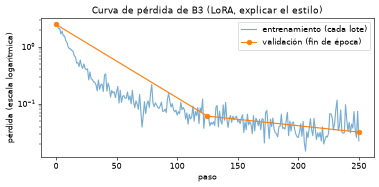

In [8]:
pasos_por_epoca = pasos / EPOCAS
plt.figure(figsize=(7, 3.5))
plt.plot(historia['paso'], historia['perdida'], alpha=0.6, label='entrenamiento (cada lote)')
plt.plot([e * pasos_por_epoca for e in historia['epoca']], historia['perdida_val'], 'o-', label='validación (fin de época)')
plt.yscale('log'); plt.xlabel('paso'); plt.ylabel('pérdida (escala logarítmica)'); plt.legend()
plt.title('Curva de pérdida de B3 (LoRA, explicar el estilo)')
plt.tight_layout()
ce.guardar_figura(resultados / 'curva_perdida_explicacion.png')
ce.guardar_figura(carpeta_img / '05_curva_perdida.png')
plt.show()

**Cómo se lee** (ejecución del 21/11/2026, 500 ejemplos, 2 épocas = 250 pasos de 4 ejemplos):

- La pérdida de validación baja de **2,464** (antes de entrenar) a **0,061** tras la época 1 y a **0,032** tras la época 2. La media de entrenamiento de cada época es 0,309 y 0,046. En la ronda 4 del estudio técnico salieron los mismos valores de validación (0,061 y 0,032).
- Está en **escala logarítmica**: la pérdida cae más de un orden de magnitud y todavía iba bajando al acabar.
- Compárala con la del notebook 03, donde la pérdida bajó de 2,758 a 0,479 y se quedó plana: **también bajaba, y el modelo no hacía la tarea**. Una curva bonita no demuestra nada por sí sola; lo que lo demuestra es la métrica contra la verdad, que miramos ahora.

## 4. Resultados de B3 en test

Guardamos el adaptador (solo las «notas a lápiz» de LoRA) y le pedimos que explique los 60 JSON de test, que no ha visto, con las mismas métricas que A3.

In [9]:
modelo.eval()
salidas_B3, m_B3 = medir(modelo, prompt_B3, 'B3')
carpeta_adaptador = trabajo / 'adaptador_explicacion'
modelo.save_pretrained(carpeta_adaptador)
m_B3.update(s_entrenamiento=c_train.s, adaptador_mb=ce.tamano_mb(carpeta_adaptador / 'adapter_model.safetensors'),
            epocas=EPOCAS, n_train=len(train))
memoria = ce.memoria_mb()
print('Adaptador:', m_B3['adaptador_mb'], 'MB | memoria pico del proceso:', memoria, 'MB')

B3 {'pct_ajustes_sentido_correcto': 100.0, 'pct_ajustes_sentido_contrario': 0.0, 'pct_frases_con_alucinacion': 18.3, 'pct_frases_espanol_longitud_ok': 100.0, 'pct_frases_perfectas': 81.7, 's_por_frase': 3.74}


Adaptador: 7.06 MB | memoria pico del proceso: 2887.0 MB


                    ajustes_sentido_correc  ajustes_sentido_contra  frases_con_alucinacion  frases_espanol_longitu        frases_perfectas  s/frase
objetivo (reglas)                   100.0%                    0.0%                    0.0%                  100.0%                  100.0%
A3 one-shot                          40.7%                   39.5%                   58.3%                    0.0%                    0.0%     3.46
B3 LoRA                             100.0%                    0.0%                   18.3%                  100.0%                   81.7%     3.74


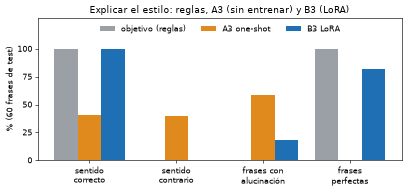

In [10]:
filas = {'objetivo (reglas)': objetivo, 'A3 one-shot': m_A3, 'B3 LoRA': m_B3}
claves = ['pct_ajustes_sentido_correcto', 'pct_ajustes_sentido_contrario', 'pct_frases_con_alucinacion',
          'pct_frases_espanol_longitud_ok', 'pct_frases_perfectas']
print(f"{'':18s}" + ''.join(f"{c.replace('pct_', '')[:22]:>24s}" for c in claves) + f"{'s/frase':>9s}")
for nombre, m in filas.items():
    print(f"{nombre:18s}" + ''.join(f'{m[c]:23.1f}%' for c in claves) + (f"{m['s_por_frase']:9.2f}" if 's_por_frase' in m else ''))

etiquetas = ['sentido\ncorrecto', 'sentido\ncontrario', 'frases con\nalucinación', 'frases\nperfectas']
cols = ['pct_ajustes_sentido_correcto', 'pct_ajustes_sentido_contrario', 'pct_frases_con_alucinacion', 'pct_frases_perfectas']
x = np.arange(len(cols)); ancho = 0.27
plt.figure(figsize=(7.5, 3.6))
for j, (nombre, color) in enumerate(zip(filas, ['#9aa0a6', '#e08a1e', '#1f6fb4'])):
    plt.bar(x + (j - 1) * ancho, [filas[nombre][c] for c in cols], ancho, label=nombre, color=color)
plt.xticks(x, etiquetas); plt.ylabel('% (60 frases de test)'); plt.ylim(0, 128); plt.yticks([0, 25, 50, 75, 100])
plt.legend(loc='upper center', ncol=3, frameon=False)
plt.title('Explicar el estilo: reglas, A3 (sin entrenar) y B3 (LoRA)')
plt.tight_layout()
ce.guardar_figura(resultados / 'comparacion_explicacion.png')
ce.guardar_figura(carpeta_img / '05_comparacion.png')
plt.show()

**Cómo se lee la tabla** (60 JSON de test que ningún modelo ha visto):

- **B3 acierta el sentido del 100 % de los ajustes y no invierte ninguno** (0 % en sentido contrario). A3 acierta el 40,7 % e invierte el 39,5 %.
- El 81,7 % de las frases de B3 son **perfectas** (A3: 0 %), y el 100 % están en español con una longitud razonable.
- El fallo que queda: el **18,3 %** de las frases de B3 mencionan un ajuste que no se tocó (alucinación).

**Esta ejecución y la ronda 4 del estudio técnico (20/11/2026)**, con la misma configuración (500 JSON fabricados, formato «facil», 2 épocas):

| | Ronda 4 (notebook, 12 hilos) | Esta ejecución (21/11/2026, 12 hilos) |
|---|---|---|
| A3: sentido correcto / contrario / alucinación / perfectas | 40,7 % / 39,5 % / 58,3 % / 0 % | 40,7 % / 39,5 % / 58,3 % / 0 % |
| B3: sentido correcto / contrario | 100 % / 0 % | 100 % / 0 % |
| B3: frases con alucinación / perfectas | 18,3 % / 81,7 % | 18,3 % / 81,7 % |
| B3: entrenamiento | 906 s | 933 s |
| B3: segundos por frase | 4,11 | 3,74 |
| A3: segundos por frase | 4,51 | 3,46 |
| Adaptador / memoria pico del proceso | 7,06 MB / 2887 MB | 7,06 MB / 2887 MB |

Las cifras de calidad coinciden; solo cambian los tiempos, que dependen del estado del portátil.

**Pero la alucinación no es estable entre ejecuciones.** En la sonda previa de la ronda 4 (6 hilos y la CPU compartida) salió un **10,0 %** de frases con alucinación (90,0 % perfectas). Una ejecución anterior de este mismo notebook, con 14 hilos, dio un **15,0 %** (85,0 % perfectas). El sentido correcto fue siempre el 100 %. Con una sola semilla y 60 frases de test, esa cifra se mueve entre el 10 % y el 18,3 % según el orden de las operaciones: no te fíes de una sola corrida.

### Seis ejemplos reales, lado a lado

Los seis primeros JSON de test, con la frase objetivo, lo que escribe A3 y lo que escribe B3 (en las respuestas largas de A3 solo se muestran los primeros 300 caracteres).

In [11]:
for f, a, b in list(zip(test, salidas_A3, salidas_B3))[:6]:
    print('\nAJUSTES :', ce.a_json(f['ajustes']))
    print('OBJETIVO:', f['frase'])
    print('A3      :', a.replace('\n', ' ')[:300])
    print('B3      :', b.replace('\n', ' ')[:300])

metricas = {'A3': m_A3, 'B3': m_B3, 'objetivo': objetivo, 's_A3_total': c_A3.s, 'memoria_pico_mb': memoria,
            'modelo': MODELO, 'formato': FORMATO, 'n_test': len(test), 'hilos': hilos, 'historia_B3': historia}
(resultados / 'metricas_explicacion.json').write_text(json.dumps(metricas, indent=1, ensure_ascii=False), encoding='utf-8')
(resultados / 'explicaciones.jsonl').write_text('\n'.join(json.dumps({'id': f['id'], 'objetivo': f['frase'], 'A3': a, 'B3': b}, ensure_ascii=False)
                                                          for f, a, b in zip(test, salidas_A3, salidas_B3)), encoding='utf-8')


AJUSTES : {"exposicion": 0.45, "temperatura": 0.5, "tinte": 0.03, "contraste": 1.35, "saturacion": 1.69}
OBJETIVO: Para copiar este estilo, se sube bastante la exposición, se sube bastante la temperatura, se sube bastante el contraste y se sube bastante la saturación.
A3      : La referencia es más luminosa, más magenta, con menos contraste y más saturada: se sube bastante la exposición, se lleva el tinte bastante hacia el magenta, se baja bastante el contraste y se sube un poco la saturación. Ejemplo: Cambios: exposicion: sube bastante; temperatura: sube bastante; tinte: 
B3      : La referencia es más luminosa, más cálida, con más contraste y más saturada: se sube bastante la exposición, se sube bastante la temperatura, se sube bastante el contraste y se sube bastante la saturación.

AJUSTES : {"exposicion": -0.58, "temperatura": -0.08, "tinte": 0.54, "contraste": 0.67, "saturacion": 1.73}
OBJETIVO: Para copiar este estilo, se baja bastante la exposición, se lleva el tinte bastante 

49302

**Qué mirar en los seis ejemplos:**

- **A3** escribe **la misma frase** en los seis (la de su ejemplo del prompt) y luego el eco «Ejemplo: Cambios: …». No mira el JSON.
- **B3** escribe frases con la forma de las plantillas y, en estos seis, **acierta el sentido de todos los ajustes**. Cinco de las seis son perfectas.
- **La quinta** (exposición 0,0) empieza con «Estilo más oscura…»: la exposición no se tocó y B3 la menciona de todos modos. Es una **alucinación** que no se ve si solo lees la frase por encima: suena natural.
- Fíjate también en «Estilo más oscura»: la concordancia es incorrecta porque **nuestra propia plantilla** («Estilo *adjetivos*») la tiene así. B3 copia con fidelidad hasta un defecto de las reglas con las que le enseñamos.

## 5. Análisis de las alucinaciones de B3

Una **alucinación** aquí es mencionar un ajuste que casi no cambia (intensidad por debajo de 0,15). Miramos **qué ajustes** se inventa B3, **cuánto valían** en realidad y **en qué parte de la frase** aparecen (los adjetivos de la cabecera o la lista de acciones).

11 frases de 60 con algún ajuste inventado (13 ajustes inventados en total)
Por ajuste: {'exposicion': 6, 'contraste': 3, 'temperatura': 2, 'tinte': 2}
|intensidad| real de los ajustes inventados: de 0.00 a 0.13 (el umbral para mencionarlos es 0.15)
Aparecen en los adjetivos de la cabecera: 11 | en la lista de acciones: 2 | solo en la lista de acciones: 2

Tres casos:
- Se inventa «exposicion» (intensidad real +0.00):
  Estilo más oscura, más fría, más magenta, con más contraste y menos saturada. Cambios: se baja un poco la temperatura, se lleva el tinte un poco hacia el magenta, se sube bastante el contraste y se baja bastante la saturación.
- Se inventa «exposicion» (intensidad real -0.01):
  Estilo más oscura, más fría, más magenta, con más contraste y más saturada. Cambios: se baja un poco la temperatura, se lleva el tinte bastante hacia el magenta, se sube un poco el contraste y se sube un poco la saturación.
- Se inventa «exposicion» (intensidad real -0.03):
  Estilo más oscura, 

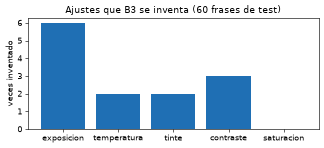

In [12]:
import re
from collections import Counter

casos = []
for f, b in zip(test, salidas_B3):
    # Cabecera = los adjetivos del principio; resto = la lista de acciones
    cabecera = re.split(r'Cambios:|:', b, maxsplit=1)[0].lower() if ':' in b else ''
    resto = b.lower()[len(cabecera):]
    for k in ce.evaluar_frase(b, f['ajustes'])['alucinados']:
        patron = ce.PATRONES[k][2]
        casos.append({'id': f['id'], 'ajuste': k, 'intensidad': ce.intensidad(k, f['ajustes'][k]), 'frase': b,
                      'en_cabecera': re.search(patron, cabecera) is not None, 'en_acciones': re.search(patron, resto) is not None})
n_frases = len({c['id'] for c in casos})
print(f'{n_frases} frases de {len(test)} con algún ajuste inventado ({len(casos)} ajustes inventados en total)')
if casos:
    por_ajuste = Counter(c['ajuste'] for c in casos)
    print('Por ajuste:', dict(por_ajuste.most_common()))
    inten = [abs(c['intensidad']) for c in casos]
    print(f'|intensidad| real de los ajustes inventados: de {min(inten):.2f} a {max(inten):.2f} (el umbral para mencionarlos es {ce.UMBRAL_NULO})')
    print('Aparecen en los adjetivos de la cabecera:', sum(c['en_cabecera'] for c in casos),
          '| en la lista de acciones:', sum(c['en_acciones'] for c in casos),
          '| solo en la lista de acciones:', sum(c['en_acciones'] and not c['en_cabecera'] for c in casos))
    print('\nTres casos:')
    for c in casos[:3]:
        print(f"- Se inventa «{c['ajuste']}» (intensidad real {c['intensidad']:+.2f}):\n  {c['frase']}")

inventados = {k: sum(c['ajuste'] == k for c in casos) for k in ce.NOMBRES}
plt.figure(figsize=(6, 2.8))
plt.bar(list(inventados), list(inventados.values()), color='#1f6fb4')
plt.ylabel('veces inventado'); plt.title('Ajustes que B3 se inventa (60 frases de test)')
plt.tight_layout()
ce.guardar_figura(resultados / 'alucinaciones_explicacion.png')
ce.guardar_figura(carpeta_img / '05_alucinaciones.png')
plt.show()

**Qué enseña el análisis** (ejecución del 21/11/2026):

- **11 de 60 frases** (18,3 %) tienen algún ajuste inventado, **13 ajustes inventados** en total: exposición 6, contraste 3, temperatura 2, tinte 2 y saturación ninguno.
- Los ajustes inventados valían de **0,00 a 0,13** de intensidad: eran ajustes **casi nulos**, justo por debajo del umbral de 0,15 de las reglas. B3 no se inventa un ajuste cualquiera, sino los que estaban cerca del límite.
- **11 aparecen en los adjetivos del principio de la frase** y 2 solo en la lista de acciones. En los tres casos mostrados es la exposición («Estilo más oscura, …») con valores casi nulos (+0,00, −0,01 y −0,03). El estudio técnico (ronda 4, 11 frases, intensidades de −0,12 a 0,13) vio lo mismo: casi siempre un adjetivo de más al principio, sobre todo «más oscura», con la lista de acciones bien.
- Qué lo provoca: no lo hemos comprobado. Una hipótesis (**sin verificar**) es que decidir si 0,10 «cuenta» o no es la parte más difícil de la regla, y que los adjetivos se escriben antes que las acciones, cuando el modelo todavía no ha «repasado» la entrada.

**Qué haríamos para bajarla** (ideas del estudio técnico, **sin verificar**): más JSON fabricados (1000 a 2000, que cuestan lo mismo de fabricar) o una plantilla sin la lista de adjetivos. Con el criterio que fijó el estudio (al menos 90 % de sentido correcto **y** como mucho 10 % de frases con alucinación), el sentido se cumple con holgura y la alucinación no: 18,3 % aquí, 10,0 % en la sonda.

**Lo importante:** ninguna de estas frases «suena mal». Solo una métrica automática contra la verdad las detecta. Un modelo fluido no es lo mismo que un modelo correcto.

## 6. Registrar en MLflow

Dos runs en la misma base `mlflow.db` de la carpeta de trabajo: `A3_explicacion_one_shot` y `B3_explicacion_lora` (con la pérdida de validación por época y el **adaptador como artefacto**), igual que en el notebook 03.

In [13]:
mlflow = ce.mlflow_local(trabajo)
with mlflow.start_run(run_name='A3_explicacion_one_shot'):
    mlflow.log_params({'version': 'A3', 'modelo': MODELO, 'formato': FORMATO, 'n_test': len(test), 'hilos': hilos})
    mlflow.log_metrics(m_A3)
with mlflow.start_run(run_name='B3_explicacion_lora'):
    mlflow.log_params({'version': 'B3', 'modelo': MODELO, 'formato': FORMATO, 'rango_lora': RANGO_LORA, 'epocas': EPOCAS,
                       'tam_lote': TAM_LOTE, 'tasa_aprendizaje': TASA_APRENDIZAJE, 'n_train': len(train), 'n_test': len(test), 'hilos': hilos})
    for e, v in zip(historia['epoca'], historia['perdida_val']):
        mlflow.log_metric('perdida_val', v, step=e)
    mlflow.log_metrics({k: v for k, v in m_B3.items() if isinstance(v, float)})
    mlflow.log_artifacts(str(carpeta_adaptador), artifact_path='adaptador_explicacion')
print('Runs en MLflow:', sorted(r.info.run_name for r in mlflow.search_runs(experiment_names=['pico-llm-estilo'], output_format='list')))
print('Base de datos:', ce.mostrar_ruta(trabajo / 'mlflow.db', trabajo))

2026/11/21 02:49:15 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/21 02:49:15 INFO mlflow.store.db.utils: Updating database tables


Runs en MLflow: ['A3_explicacion_one_shot', 'B3_explicacion_lora']
Base de datos: <trabajo>/mlflow.db


## 7. Conclusión: los tres actos

| Acto | Qué se le pide al LLM | Datos de entrenamiento | Resultado |
|---|---|---|---|
| **1** · notebooks 02 y 03 | **Ver**: foto → JSON con cinco números | 210 fotos editadas (solo preparar la imagen costó unos 2,2 s por foto) | Aprende el formato (100 % de JSON válidos) pero **no la tarea**: error 0,310, peor que contestar la media (0,259) |
| **2** · notebook 04 | (no es un LLM) regresión sobre 27 estadísticas de color | las mismas 210 fotos | Gana: error 0,151, en segundos |
| **3** · este notebook | **Redactar**: JSON → frase en español | 500 JSON fabricados, **gratis** | **100 % de sentidos correctos**, 0 % contrarios, 81,7 % de frases perfectas; pero 18,3 % de frases con algún ajuste inventado |

Qué nos dice el conjunto:

1. **Aquí el fine-tuning sí funciona, porque la tarea es de lenguaje.** Convertir información estructurada en texto es lo que mejor hace un LLM. En el acto 1 el LoRA bajaba la pérdida y no aprendía a ver el color; en el acto 3 la pérdida baja **y** la métrica contra la verdad lo confirma.
2. **Qué cambió respecto al primer intento** (ronda 3 del estudio técnico: 210 JSON de las parejas y entrada en formato «json»: 60,5 % de sentido correcto, 38,7 % en sentido contrario, 58,3 % de frases con alucinación y 6,7 % de perfectas). Cambiaron **dos cosas a la vez**: más datos (500 en vez de 210, y fabricarlos es gratis) y una entrada más fácil (el sentido y la intensidad ya vienen calculados por las reglas y el modelo **solo redacta**). Como se cambiaron juntas, no sabemos cuánto aporta cada una.
3. **Fluido no es lo mismo que correcto.** Con el 100 % de sentidos correctos, B3 todavía se inventa algún adjetivo en el 18,3 % de las frases, y esa cifra se mueve entre ejecuciones (10,0 %, 15,0 % y 18,3 % con la misma configuración). **Hay que medir las alucinaciones**, con una métrica automática y más de una corrida.
4. **Divide el trabajo.** Las reglas (o un modelo como el del acto 2) deciden **qué** decir; el LLM decide **cómo** decirlo. De hecho, las reglas ya producen la frase perfecta sin entrenar nada: el LLM solo compensa si necesitas variedad o un tono que las plantillas no dan (algo que aquí **no se ha medido**).

Y, para producción, `evaluar_frase` es barata: se puede ejecutar sobre cada frase generada antes de enseñarla al usuario.

## Qué te llevas

- **Un LLM pequeño con LoRA sí aprende una tarea de lenguaje**: con 500 JSON fabricados y 2 épocas (unos 15 minutos de entrenamiento en CPU), escribe frases con el 100 % de los sentidos correctos. El adaptador pesa **7,06 MB**.
- **Los datos de texto pueden salir gratis de unas reglas**, y esas mismas reglas dan la verdad contra la que medir. Ahí está la diferencia con el acto 1, donde cada ejemplo necesitaba una foto.
- **Sin entrenar, un ejemplo en el prompt no basta** (A3: 40,7 % de sentidos correctos y 58,3 % de frases con alucinación): el modelo imita en vez de entender.
- **Fluido no es lo mismo que correcto.** El 18,3 % de las frases de B3 se inventan un ajuste, y esa cifra varió entre ejecuciones (10,0 %, 15,0 % y 18,3 %). Mide siempre con una métrica contra la verdad y no te fíes de una sola corrida.
- **Reparte el trabajo**: las reglas deciden qué decir y el LLM cómo decirlo.

## Preguntas para pensar

1. B3 acierta el sentido del 100 % de los ajustes, pero en el 18,3 % de las frases menciona un ajuste que no se tocó. Si la frase la va a leer un usuario, ¿cómo usarías `evaluar_frase` dentro de una aplicación para decidir qué hacer con una frase que falla (descartarla, regenerarla, devolver la frase de las reglas)? ¿Qué porcentaje de alucinación tolerarías y por qué?
2. Las reglas ya generan la frase perfecta (100 %) sin entrenar nada y sin LLM. ¿Qué tendrías que **medir** para decidir si compensa pagar un LLM (variedad de las frases, tono, coste, mantenimiento)? En este estudio no se midió ninguna de esas cosas.

**Siguiente:** como los demás notebooks, este tiene una celda `parameters` y lee y escribe en la carpeta de trabajo, así que se puede ejecutar con papermill desde un flujo de integración continua y guardar sus resultados y el adaptador como artefactos.